# Objectifs d'apprentissage – Semaine 10

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les différentes structures d'implémentation des filtres RIF et RII.
- **Implémenter** un filtre RIF sous forme directe et en cascade.
- **Implémenter** un filtre RII sous forme directe I, directe II, cascade et parallèle.
- **Analyser** l'influence de la structure sur les performances (stabilité, bruit de calcul).
- **Évaluer** le retard de groupe et la phase d'un filtre.
- **Simuler** les effets de la quantification en virgule fixe sur un filtre numérique.
- **Comparer** les filtres RIF et RII en termes de complexité, phase et stabilité.
- **Utiliser** Python pour l'implémentation et l'analyse de filtres numériques.

# 1. Rappels théoriques

## 1.1 Structures pour les filtres RIF

Un filtre RIF (FIR) est défini par l'équation aux différences :
$$ y[n] = \sum_{k=0}^{M} b_k \, x[n-k] $$

### Structure directe (transversale)
C'est l'implémentation directe de la convolution. Elle est simple et stable, mais peut nécessiter beaucoup de multiplications si l'ordre est élevé.

### Structure en cascade
On factorise la fonction de transfert en sections du second ordre (SOS) :
$$ H(z) = \prod_{k} H_k(z) $$
avec $H_k(z) = b_{0k} + b_{1k} z^{-1} + b_{2k} z^{-2}$.
Cela permet de réduire les effets de quantification et d'implémenter des filtres de grande longueur.

### Structure pour phase linéaire
Si les coefficients sont symétriques, on peut réduire le nombre de multiplications par 2.

## 1.2 Structures pour les filtres RII

Un filtre RII (IIR) est défini par :
$$ \sum_{k=0}^{N} a_k \, y[n-k] = \sum_{k=0}^{M} b_k \, x[n-k] $$
avec $a_0 = 1$.

### Forme directe I
Sépare les parties feedforward (numérateur) et feedback (dénominateur).

### Forme directe II
Réduction du nombre de registres en partageant les retards. Plus économe en mémoire.

### Forme en cascade
Factorisation en sections du second ordre (biquad) : $H(z) = \prod H_k(z)$.
Chaque section est stable si ses pôles sont à l'intérieur du cercle unité.
Cette structure minimise les effets de la quantification et est la plus utilisée en pratique.

### Forme parallèle
Décomposition en fractions partielles : $H(z) = K + \sum \frac{r_k}{1 - p_k z^{-1}}$.
Utilisée parfois pour des filtres à pôles réels.

## 1.3 Retard de groupe
Le retard de groupe $\tau_g(\omega)$ est défini par :
$$ \tau_g(\omega) = -\frac{d}{d\omega} \arg H(e^{j\omega}) $$
Il mesure la distorsion de phase. Pour un filtre à phase linéaire, $\tau_g$ est constant.

## 1.4 Effets de la quantification
En implémentation réelle (processeur DSP, FPGA), les coefficients et les calculs sont quantifiés. Cela peut entraîner :
- Erreurs de troncature/arrondi.
- Bruit de quantification en sortie.
- Oscillations (limit cycles) pour les filtres RII.

---

# 2. Démonstrations Python

## 2.1 Implémentation d'un filtre RIF – Structure directe

Nous allons implémenter un filtre RIF passe-bas en utilisant la convolution directe et comparer avec `lfilter`.

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


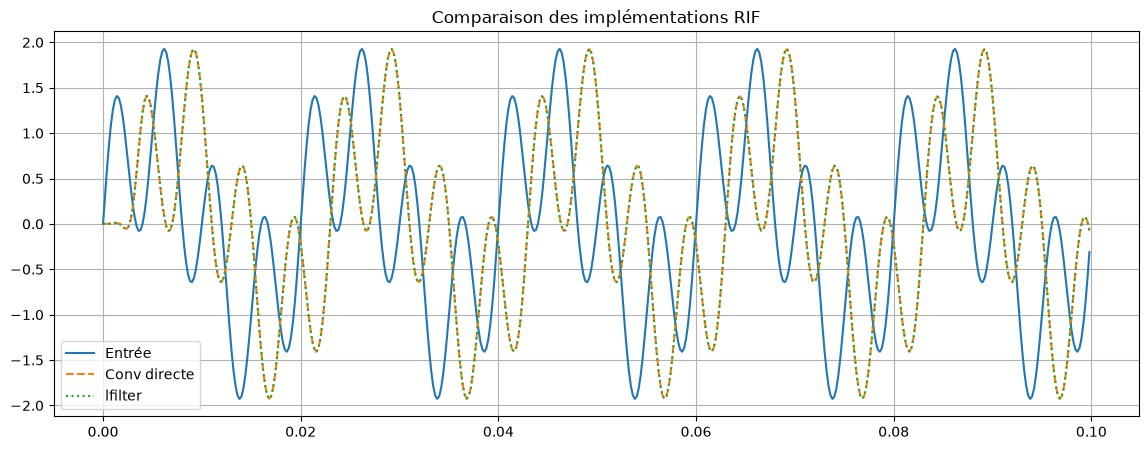

Erreur max entre les deux : 0.0


In [40]:
# Conception d'un filtre RIF passe-bas
fs = 1000
fc = 100
N = 31  # ordre 30
b = signal.firwin(N, fc, fs=fs, window='hamming')

# Implémentation directe par convolution
def fir_filter(x, b):
    y = np.convolve(x, b, mode='full')
    return y[:len(x)]  # on tronque pour garder la même longueur

# Signal test
t = np.linspace(0, 0.1, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*200*t)

y_conv = fir_filter(x, b)
y_lfilter = signal.lfilter(b, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_conv, '--', label='Conv directe')
plt.plot(t, y_lfilter, ':', label='lfilter')
plt.legend()
plt.grid()
plt.title('Comparaison des implémentations RIF')
plt.show()
print("Erreur max entre les deux :", np.max(np.abs(y_conv - y_lfilter)))

## 2.2 Structure en cascade pour RIF

Décomposons un filtre RIF en sections du second ordre.

Nombre de sections : 15
[[ 1.20142638e-03 -3.50782491e-03  2.66704843e-03  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -7.60763806e-01  1.13993205e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -4.45897340e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.90247028e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.17819278e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  1.48805025e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  8.16718191e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  4.18723996e-01  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -1.09876196e+00  1.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00 -9.65981738e-04  1.00000000e+00  1.00000000e+00
 

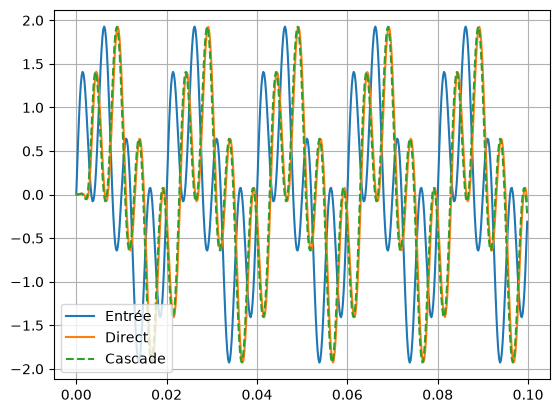

Erreur max : 0.3110169989336258


In [41]:
# Utilisation de scipy.signal.tf2sos pour obtenir les sections
sos = signal.tf2sos(b, 1)
print(f"Nombre de sections : {len(sos)}")
print(sos)

# Implémentation en cascade
def fir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        # a_section = section[3:]  # pour RIF, a = [1, 0, 0] car section purement feedforward
        y = signal.lfilter(b_section, [1], y)
    return y

y_cascade = fir_sos_filter(x, sos)

plt.plot(t, x, label='Entrée')
plt.plot(t, y_lfilter, label='Direct')
plt.plot(t, y_cascade, '--', label='Cascade')
plt.legend()
plt.grid()
plt.show()
print("Erreur max :", np.max(np.abs(y_lfilter - y_cascade)))

## 2.3 Structures pour les filtres RII

Nous allons concevoir un filtre RII (Butterworth) et l'implémenter dans différentes structures.

Nombre de sections : 2


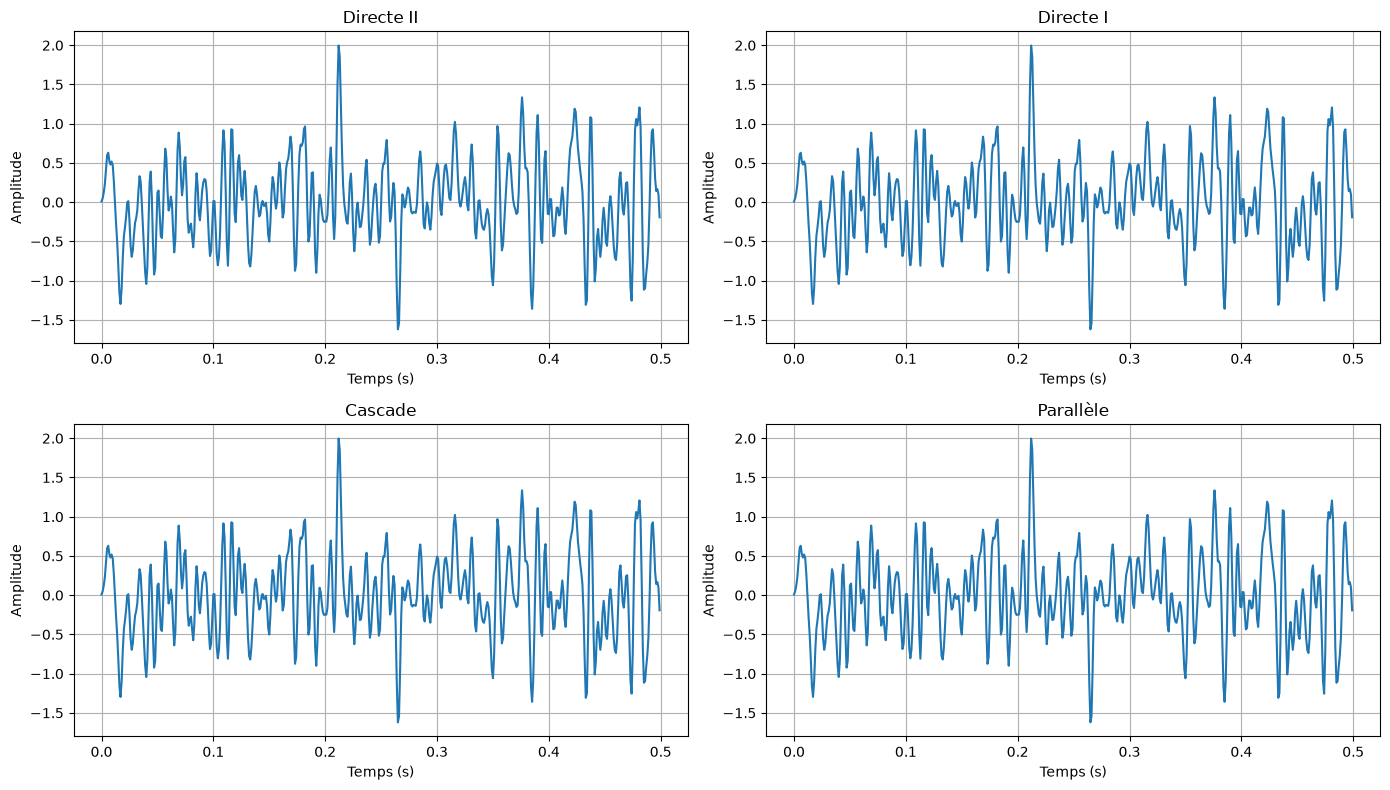

Erreur max Directe I vs Directe II : 1.4432899320127035e-15
Erreur max Cascade vs Directe II : 2.6645352591003757e-15
Erreur max Parallèle vs Directe II : 4.884981308350689e-15


In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Paramètres du signal
fs = 1000
fc = 150
N = 500
t = np.arange(N) / fs

np.random.seed(42)
x = np.random.randn(N)

# Conception d'un filtre RII passe-bas Butterworth ordre 4
order = 4
b, a = signal.butter(order, fc, fs=fs, btype='low')

# Forme directe II
y_direct2 = signal.lfilter(b, a, x)

# Forme directe I (implémentation manuelle)
def iir_direct1(x, b, a):
    N = len(x)
    M = len(b) - 1
    N_a = len(a) - 1

    y = np.zeros(N)
    x_buf = np.zeros(M+1)
    y_buf = np.zeros(N_a+1)

    for n in range(N):
        x_buf[1:] = x_buf[:-1]
        x_buf[0] = x[n]

        y_buf[1:] = y_buf[:-1]

        y[n] = np.dot(b, x_buf) - np.dot(a[1:], y_buf[1:])
        y_buf[0] = y[n]

    return y

y_direct1 = iir_direct1(x, b, a)

# Forme en cascade (sections biquad)
sos_iir = signal.tf2sos(b, a)

print("Nombre de sections :", len(sos_iir))

def iir_sos_filter(x, sos):
    y = x.copy()

    for section in sos:
        b_section = section[:3]
        a_section = section[3:]
        y = signal.lfilter(b_section, a_section, y)

    return y

y_sos = iir_sos_filter(x, sos_iir)

# Forme parallèle (décomposition en fractions partielles)
r, p, k = signal.residuez(b, a)

def iir_parallel(x, r, p, k):
    y = np.zeros(len(x), dtype=complex)

    # Terme direct
    if len(k) > 0:
        y += k[0] * x

    # Chaque fraction
    for ri, pi in zip(r, p):
        b_sec = [ri]
        a_sec = [1, -pi]
        y += signal.lfilter(b_sec, a_sec, x)

    return np.real_if_close(y)

y_parallel = iir_parallel(x, r, p, k)

# Comparaison des quatre structures
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.plot(t, y_direct2)
plt.title('Directe II')
plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_direct1)
plt.title('Directe I')
plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2, 2, 3)
plt.plot(t, y_sos)
plt.title('Cascade')
plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2, 2, 4)
plt.plot(t, y_parallel)
plt.title('Parallèle')
plt.xlabel('Temps (s)')
plt.ylabel('Amplitude')
plt.grid()

plt.tight_layout()
plt.show()

# Vérification des erreurs
print("Erreur max Directe I vs Directe II :",
      np.max(np.abs(y_direct1 - y_direct2)))

print("Erreur max Cascade vs Directe II :",
      np.max(np.abs(y_sos - y_direct2)))

print("Erreur max Parallèle vs Directe II :",
      np.max(np.abs(y_parallel - y_direct2)))

## 2.4 Analyse du retard de groupe

Calculons le retard de groupe pour un filtre RIF (phase linéaire) et un filtre RII.

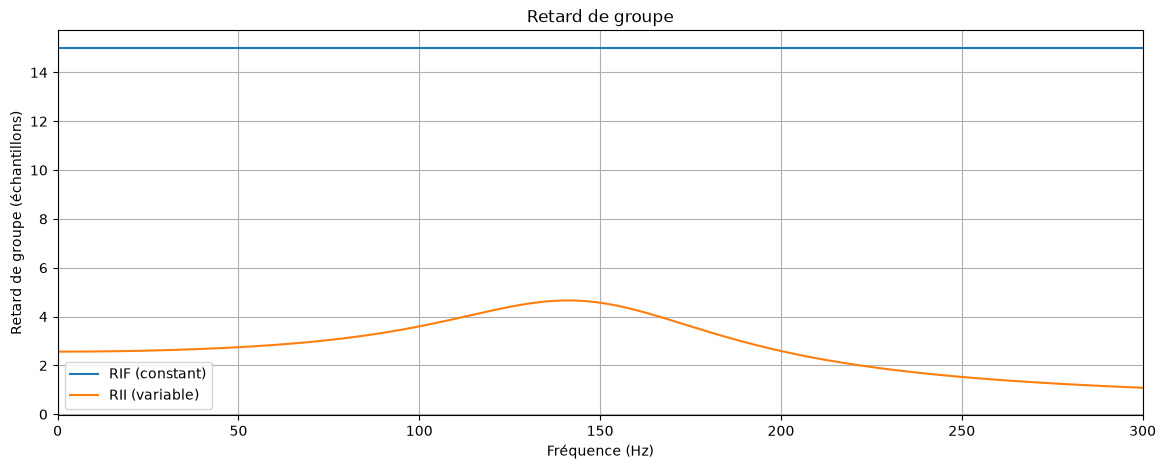

Retard de groupe du RIF : 15.00 échantillons
Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Paramètres
fs = 1000
fc = 150

# Conception du filtre RIF symétrique d'ordre 30
b = signal.firwin(31, fc, fs=fs, window='hamming')
a_fir = [1]

# Conception du filtre RII Butterworth
b_iir, a_iir = signal.butter(4, fc, fs=fs, btype='low')

# Calcul du retard de groupe
w_fir, gd_fir = signal.group_delay((b, a_fir), w=1024)
w_iir, gd_iir = signal.group_delay((b_iir, a_iir), w=1024)

# Conversion en fréquence (Hz)
freqs_fir = w_fir * fs / (2*np.pi)
freqs_iir = w_iir * fs / (2*np.pi)

# Tracé
plt.figure(figsize=(14, 5))
plt.plot(freqs_fir, gd_fir, label='RIF (constant)')
plt.plot(freqs_iir, gd_iir, label='RII (variable)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Retard de groupe (échantillons)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.title('Retard de groupe')
plt.show()

# Affichage du retard
print(f"Retard de groupe du RIF : {gd_fir[0]:.2f} échantillons")
print("Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.")

## 2.5 Simulation des effets de quantification

Simulons un filtre RII en virgule fixe (représentation Q15) pour observer l'impact sur la réponse.

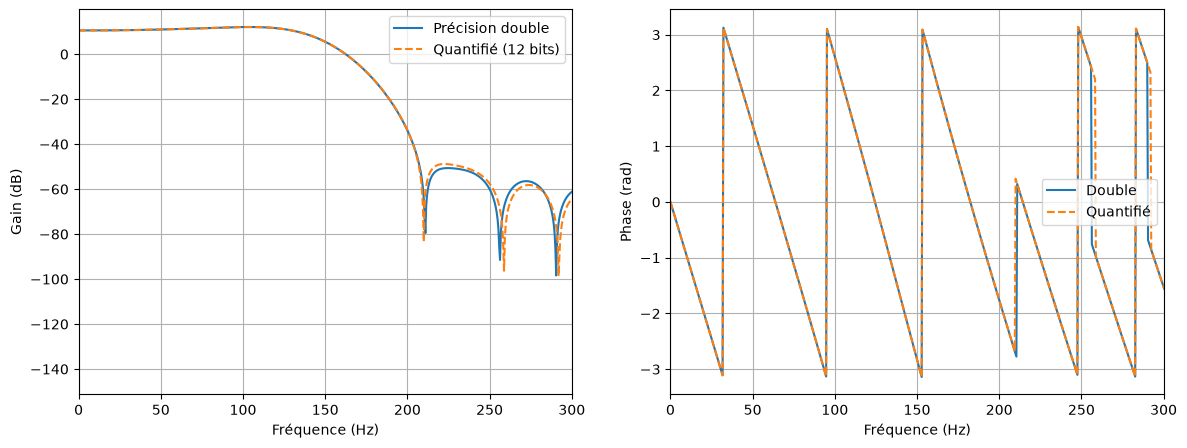

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


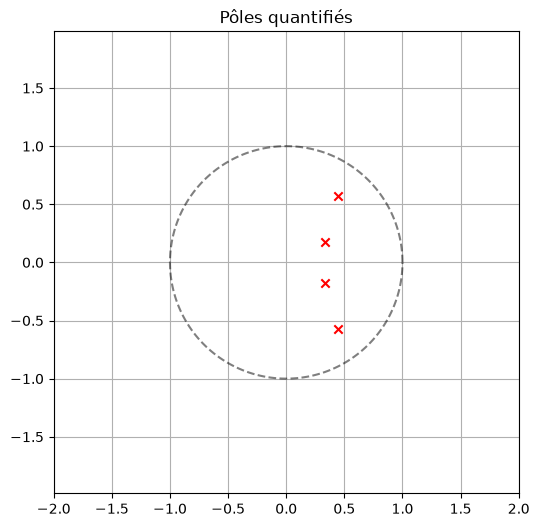

Filtre quantifié stable : True


In [44]:
def quantize_coeffs(coeffs, n_bits=16, scale=1.0):
    """Quantifie des coefficients sur n_bits avec mise à l'échelle."""
    # Qn format : valeurs entre -1 et 1 représentées sur n_bits
    max_val = 2**(n_bits-1) - 1
    coeffs_scaled = coeffs * scale
    coeffs_int = np.round(coeffs_scaled * max_val)
    coeffs_q = coeffs_int / max_val
    return coeffs_q / scale  # remettre à l'échelle

# Quantification des coefficients du RII
b_q = quantize_coeffs(b, n_bits=12)
a_q = quantize_coeffs(a, n_bits=12)

# Réponses fréquentielles
w, H = signal.freqz(b, a, worN=1024)
w, H_q = signal.freqz(b_q, a_q, worN=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)), label='Précision double')
plt.plot(freqs, 20*np.log10(np.abs(H_q)), '--', label='Quantifié (12 bits)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.angle(H), label='Double')
plt.plot(freqs, np.angle(H_q), '--', label='Quantifié')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

# Pôles quantifiés
zeros, poles, gain = signal.tf2zpk(b_q, a_q)
plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r')
plt.axis('equal')
plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.title('Pôles quantifiés')
plt.grid()
plt.show()

# Vérification de la stabilité
stable = all(np.abs(p) < 1 for p in poles)
print(f"Filtre quantifié stable : {stable}")

# 3. Atelier : Conception et analyse d'un filtre

Nous allons concevoir un filtre coupe-bande (notch) à 50 Hz en utilisant différentes structures et analyser leurs performances.

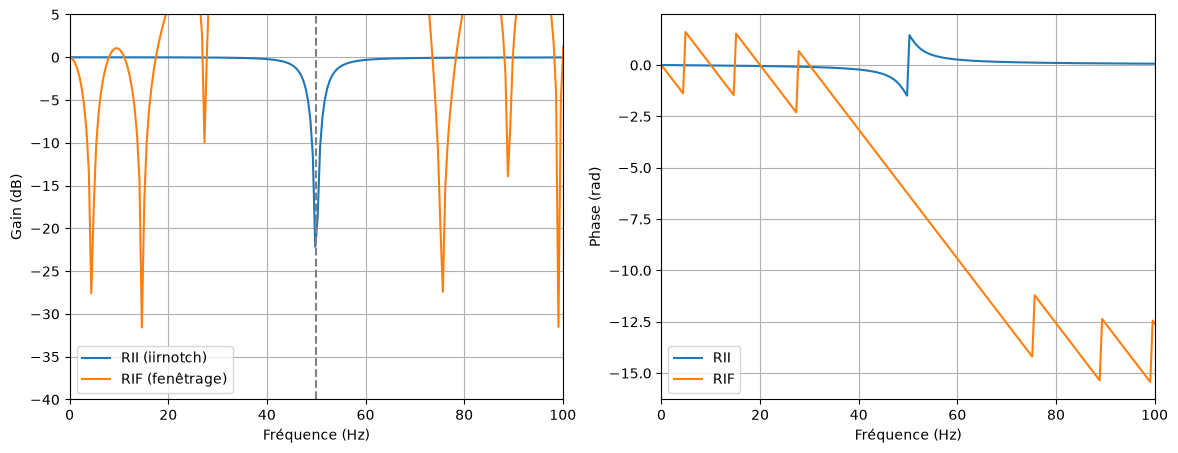

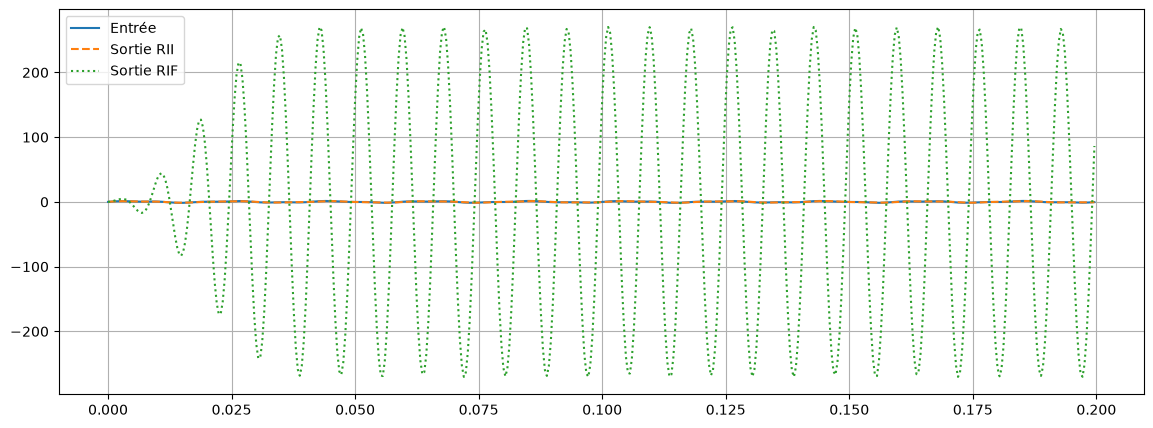

In [45]:
fs = 1000
f0 = 50
Q = 10

# Filtre notch RII (iirnotch)
b_notch, a_notch = signal.iirnotch(f0, Q, fs)

# Filtre notch RIF (fenêtre de Hamming, longueur 101)
N_notch = 101
# Conception par échantillonnage fréquentiel simple
# On va construire un filtre RIF coupe-bande en utilisant la méthode du fenêtrage
# mais pour un notch, on peut utiliser la formule de la réponse impulsionnelle idéale
# d'un coupe-bande : h_ideal[n] = (sin(omega_c2 n) - sin(omega_c1 n))/(pi n)
# avec omega_c1 = 2*pi*(f0 - BW/2)/fs, omega_c2 = 2*pi*(f0 + BW/2)/fs
BW = 10  # Hz
wc1 = 2*np.pi*(f0 - BW/2)/fs
wc2 = 2*np.pi*(f0 + BW/2)/fs
n = np.arange(-(N_notch-1)//2, (N_notch-1)//2 + 1)
h_ideal = np.zeros_like(n, dtype=float)
for i, n_i in enumerate(n):
    if n_i == 0:
        h_ideal[i] = (wc2 - wc1) / np.pi
    else:
        h_ideal[i] = (np.sin(wc2 * n_i) - np.sin(wc1 * n_i)) / (np.pi * n_i)
# Fenêtre de Hamming
window = np.hamming(N_notch)
h_fir = h_ideal * window
h_fir = h_fir / np.sum(h_fir)  # normalisation

# Réponses
w, H_notch_iir = signal.freqz(b_notch, a_notch, worN=1024)
w, H_notch_fir = signal.freqz(h_fir, 1, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_notch_iir)), label='RII (iirnotch)')
plt.plot(freqs, 20*np.log10(np.abs(H_notch_fir)), label='RIF (fenêtrage)')
plt.axvline(f0, color='gray', linestyle='--')
plt.xlim(0, 100)
plt.ylim(-40, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H_notch_iir)), label='RII')
plt.plot(freqs, np.unwrap(np.angle(H_notch_fir)), label='RIF')
plt.xlim(0, 100)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.legend()
plt.grid()
plt.show()

# Test sur signal
t = np.linspace(0, 0.2, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y_iir = signal.lfilter(b_notch, a_notch, x)
y_fir = signal.lfilter(h_fir, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_iir, '--', label='Sortie RII')
plt.plot(t, y_fir, ':', label='Sortie RIF')
plt.legend()
plt.grid()
plt.show()

# 4. Exercices – Semaine 10

## Exercice 1 – Implémentation d'un filtre RIF en structure symétrique

Pour un filtre RIF à phase linéaire de longueur impaire, les coefficients sont symétriques. Écrire une fonction `fir_linear_phase(x, b)` qui exploite la symétrie pour réduire le nombre de multiplications de moitié. Tester avec un filtre de longueur 31.

**Code** :

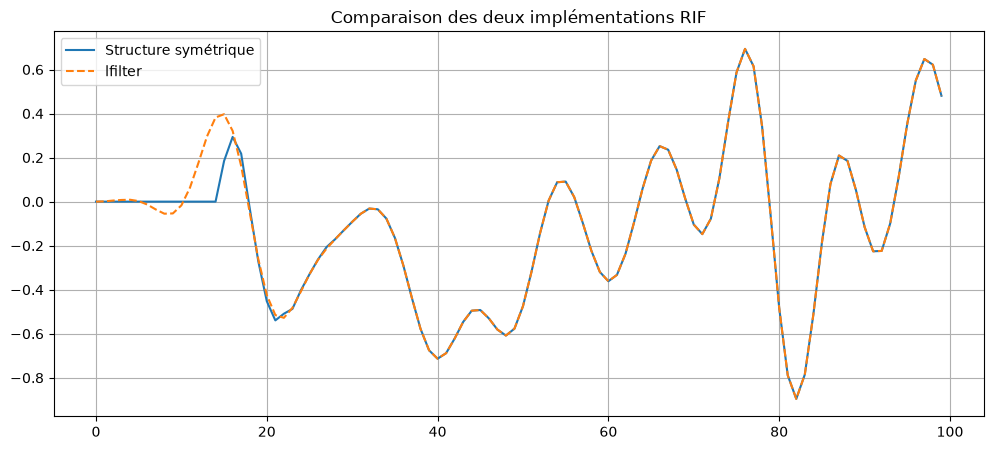

Erreur maximale : 0.3822199974538234


In [46]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

def fir_linear_phase(x, b):
    M = len(b)

    if M % 2 == 0:
        raise ValueError("La longueur doit être impaire")

    if not np.allclose(b, b[::-1]):
        raise ValueError("Les coefficients doivent être symétriques")

    y = np.zeros(len(x))
    center = M // 2

    for n in range(len(x)):
        for k in range(center):
            i1 = n - k
            i2 = n - (M - 1 - k)

            if i1 >= 0 and i2 >= 0:
                y[n] += b[k] * (x[i1] + x[i2])

        i_center = n - center
        if i_center >= 0:
            y[n] += b[center] * x[i_center]

    return y


# Conception du filtre RIF
fs = 1000
fc = 100
b_fir = signal.firwin(31, fc, fs=fs)

# Signal test
x_test = np.random.randn(100)

# Filtrage par structure symétrique
y_sym = fir_linear_phase(x_test, b_fir)

# Filtrage classique
y_ref = signal.lfilter(b_fir, 1, x_test)

# Comparaison
plt.figure(figsize=(12, 5))
plt.plot(y_sym, label="Structure symétrique")
plt.plot(y_ref, '--', label="lfilter")
plt.legend()
plt.grid()
plt.title("Comparaison des deux implémentations RIF")
plt.show()

print("Erreur maximale :", np.max(np.abs(y_sym - y_ref)))

## Exercice 2 – Filtre RII en cascade vs directe

1. Concevoir un filtre RII elliptique passe-bas avec les spécifications suivantes :
   - Fréquence de coupure 200 Hz, fs=1000 Hz.
   - Atténuation de 60 dB dans la bande stop à partir de 250 Hz.
   - Ondulation en bande passante : 0.5 dB.
2. Obtenir la forme en cascade (sos) et la forme directe.
3. Comparer les réponses en gain et en phase des deux formes.
4. Quantifier les coefficients sur 12 bits et observer l'impact sur la stabilité pour les deux structures.

**Code** :

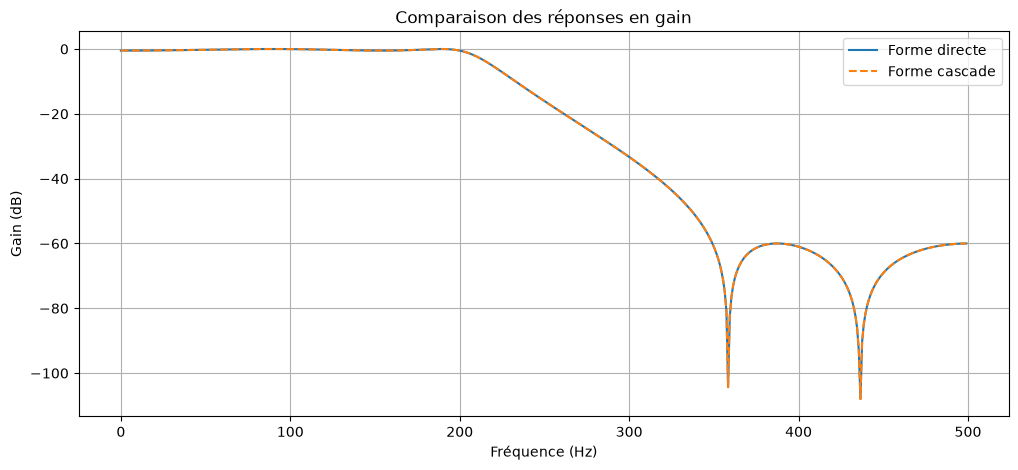

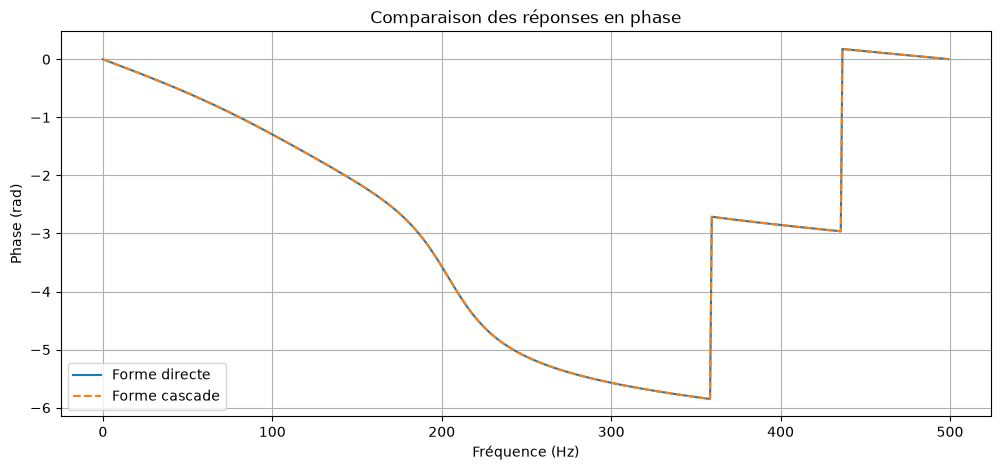

Stabilité forme directe : True
Stabilité forme cascade : True
Pôles forme directe : [0.24410925+0.82362056j 0.24410925-0.82362056j 0.43517752+0.35083715j
 0.43517752-0.35083715j]
Pôles forme cascade : [np.complex128(0.43527112848070354+0.3509867620637044j), np.complex128(0.43527112848070354-0.3509867620637044j), np.complex128(0.24425989252564723+0.8234087565303239j), np.complex128(0.24425989252564723-0.8234087565303239j)]


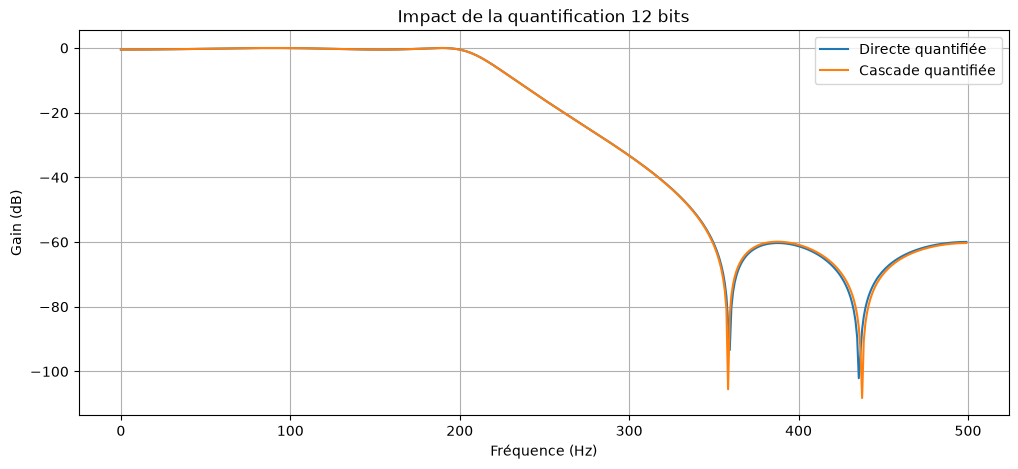

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# 1. Conception du filtre elliptique
fs = 1000
fc = 200
f_stop = 250
rp = 0.5
rs = 60
order = 4

b, a = signal.ellip(order, rp, rs, fc, fs=fs, btype='low')
sos = signal.ellip(order, rp, rs, fc, fs=fs, btype='low', output='sos')

# 2. Comparaison forme directe et cascade

# Réponse fréquentielle
w, h_direct = signal.freqz(b, a, fs=fs)
w, h_cascade = signal.sosfreqz(sos, fs=fs)

# Gain
plt.figure(figsize=(12, 5))
plt.plot(w, 20*np.log10(np.maximum(np.abs(h_direct), 1e-12)), label="Forme directe")
plt.plot(w, 20*np.log10(np.maximum(np.abs(h_cascade), 1e-12)), '--', label="Forme cascade")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.title("Comparaison des réponses en gain")
plt.grid()
plt.legend()
plt.show()

# Phase
plt.figure(figsize=(12, 5))
plt.plot(w, np.unwrap(np.angle(h_direct)), label="Forme directe")
plt.plot(w, np.unwrap(np.angle(h_cascade)), '--', label="Forme cascade")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Phase (rad)")
plt.title("Comparaison des réponses en phase")
plt.grid()
plt.legend()
plt.show()

# 3. Quantification sur 12 bits
def quantize(coeffs, bits=12):
    max_val = 2**(bits-1) - 1
    return np.round(coeffs * max_val) / max_val

# Quantification forme directe
b_q = quantize(b, 12)
a_q = quantize(a, 12)
a_q[0] = 1.0

# Quantification forme cascade (SOS)
sos_q = sos.copy()

for i in range(len(sos_q)):
    sos_q[i, :3] = quantize(sos_q[i, :3], 12)
    sos_q[i, 3:] = quantize(sos_q[i, 3:], 12)
    sos_q[i, 3] = 1.0

# 4. Vérification de stabilité
poles_direct = np.roots(a_q)
stable_direct = np.all(np.abs(poles_direct) < 1)

poles_sos = []
for section in sos_q:
    poles_sos.extend(np.roots(section[3:]))

stable_sos = np.all(np.abs(poles_sos) < 1)

print("Stabilité forme directe :", stable_direct)
print("Stabilité forme cascade :", stable_sos)
print("Pôles forme directe :", poles_direct)
print("Pôles forme cascade :", poles_sos)

# Comparaison des réponses après quantification
w, h_q_direct = signal.freqz(b_q, a_q, fs=fs)
w, h_q_sos = signal.sosfreqz(sos_q, fs=fs)

plt.figure(figsize=(12, 5))
plt.plot(w, 20*np.log10(np.maximum(np.abs(h_q_direct), 1e-12)), label="Directe quantifiée")
plt.plot(w, 20*np.log10(np.maximum(np.abs(h_q_sos), 1e-12)), label="Cascade quantifiée")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.title("Impact de la quantification 12 bits")
plt.grid()
plt.legend()
plt.show()

## Exercice 3 – Analyse du retard de groupe d'un filtre RIF et RII

1. Concevoir un filtre RIF passe-bas de type window (Hamming) avec fc=150 Hz, fs=1000 Hz, ordre 50.
2. Concevoir un filtre RII Butterworth d'ordre 6 avec les mêmes spécifications.
3. Tracer le retard de groupe des deux filtres sur la bande passante.
4. Commenter la distorsion de phase introduite par chaque filtre.

**Code** :

C:\Users\ASUSS\AppData\Local\Temp\ipykernel_10244\539810598.py:17: UserWarning: The filter's denominator is extremely small at frequencies [3.135, 3.139], around which a singularity may be present
  w_iir, gd_iir = signal.group_delay((b_iir6, a_iir6), w=1024)


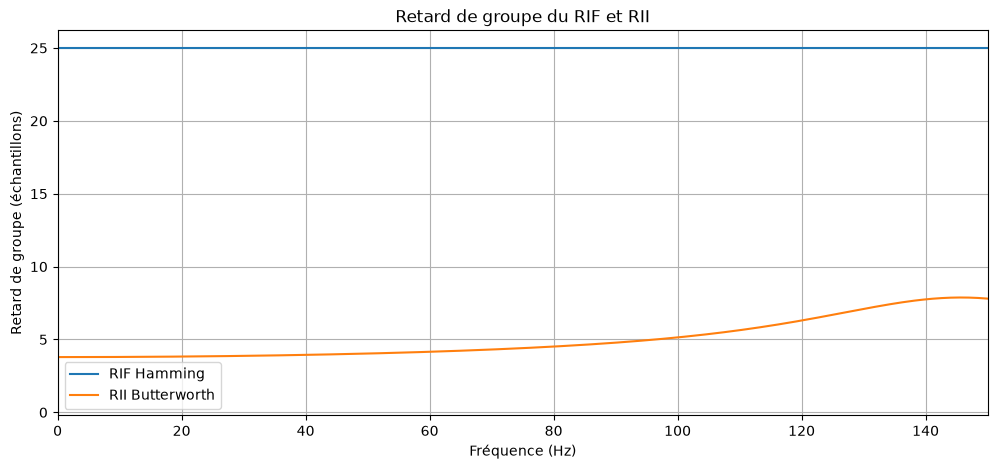

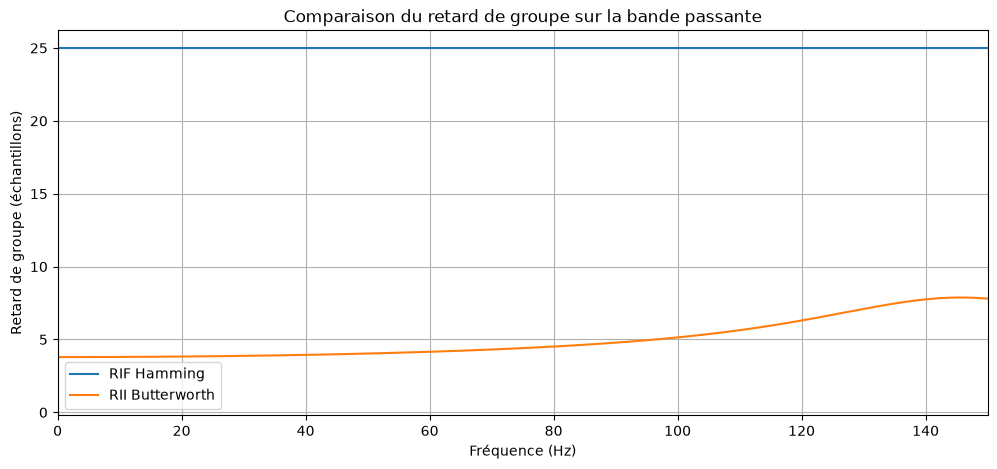

Retard théorique RIF : 25 échantillons


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs = 1000
fc = 150

# Conception du filtre RIF
b_fir50 = signal.firwin(51, fc, fs=fs, window='hamming')
a_fir50 = [1]

# Conception du filtre RII Butterworth
b_iir6, a_iir6 = signal.butter(6, fc, fs=fs, btype='low')

# Calcul du retard de groupe
w_fir, gd_fir = signal.group_delay((b_fir50, a_fir50), w=1024)
w_iir, gd_iir = signal.group_delay((b_iir6, a_iir6), w=1024)

# Conversion en fréquence (Hz)
freq_fir = w_fir * fs / (2*np.pi)
freq_iir = w_iir * fs / (2*np.pi)

# Tracé du retard de groupe
plt.figure(figsize=(12, 5))
plt.plot(freq_fir, gd_fir, label="RIF Hamming")
plt.plot(freq_iir, gd_iir, label="RII Butterworth")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Retard de groupe (échantillons)")
plt.title("Retard de groupe du RIF et RII")
plt.xlim(0, 150)
plt.grid()
plt.legend()
plt.show()

# Comparaison sur la bande passante
plt.figure(figsize=(12, 5))
plt.plot(freq_fir, gd_fir, label="RIF Hamming")
plt.plot(freq_iir, gd_iir, label="RII Butterworth")
plt.xlim(0, fc)
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Retard de groupe (échantillons)")
plt.title("Comparaison du retard de groupe sur la bande passante")
plt.grid()
plt.legend()
plt.show()

# Retard théorique du RIF
print("Retard théorique RIF :", (51-1)//2, "échantillons")

## Exercice 4 – Effet du nombre de bits sur la réponse d'un filtre RII

Pour un filtre RII passe-bande (Butterworth ordre 4, bande 100-200 Hz, fs=1000 Hz) :
1. Quantifier les coefficients avec différentes résolutions (8, 10, 12, 16 bits).
2. Pour chaque résolution, tracer la réponse en gain et repérer les dégradations.
3. Observer le déplacement des pôles et déterminer la résolution minimale pour garantir la stabilité.

**Code** :

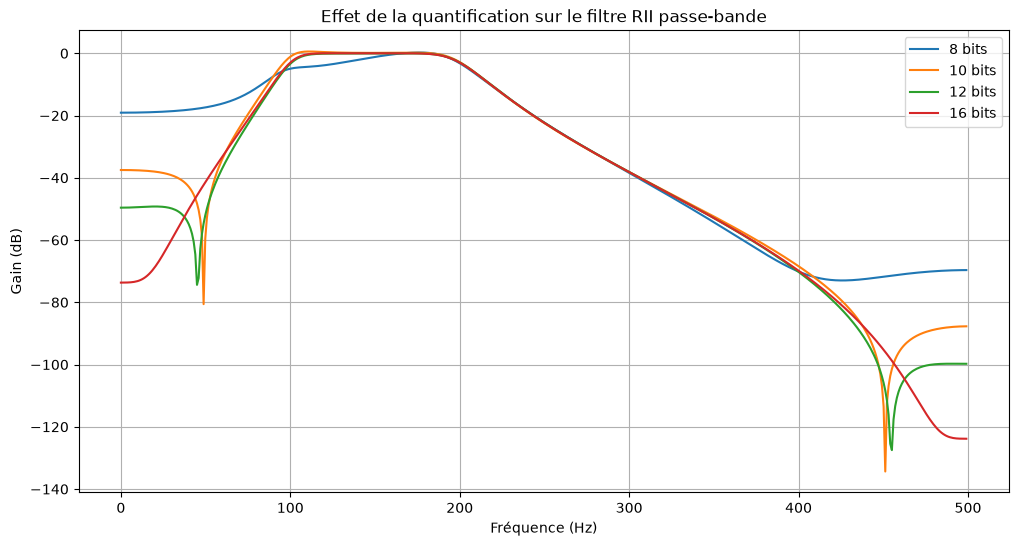

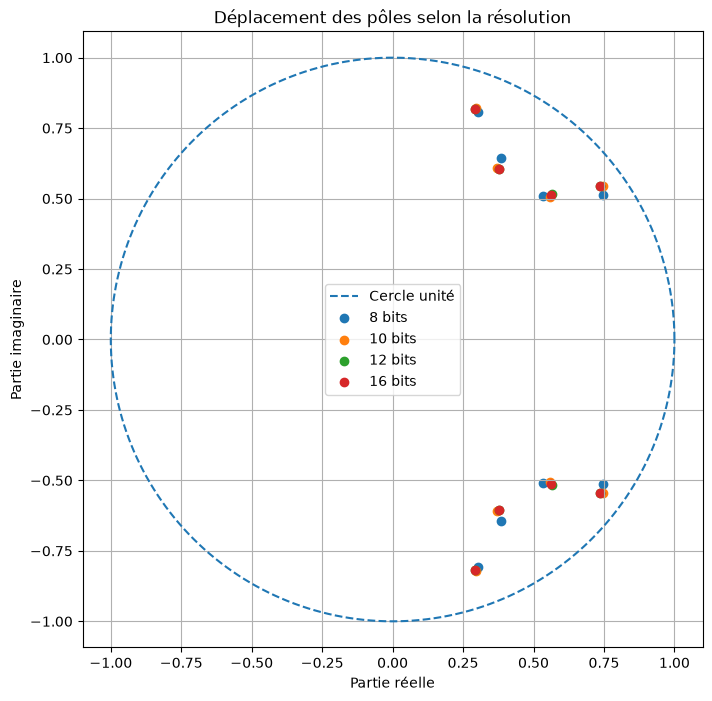

Résultats de stabilité :
8 bits | Stable : True | Module maximal des pôles : 0.906215
10 bits | Stable : True | Module maximal des pôles : 0.922282
12 bits | Stable : True | Module maximal des pôles : 0.914708
16 bits | Stable : True | Module maximal des pôles : 0.915027


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Paramètres
fs = 1000
order = 4
f_low = 100
f_high = 200
bits_list = [8, 10, 12, 16]

# Conception du filtre RII Butterworth passe-bande
b, a = signal.butter(
    order, [f_low, f_high], fs=fs, btype='bandpass'
)

# Quantification des coefficients
def quantize_coefficients(coeffs, bits):
    step = 2**(-(bits-1))
    return np.round(coeffs / step) * step

# Cercle unité
theta = np.linspace(0, 2*np.pi, 500)

# Tracé des réponses fréquentielles
plt.figure(figsize=(12, 6))

stability_results = []

for bits in bits_list:
    b_q = quantize_coefficients(b, bits)
    a_q = quantize_coefficients(a, bits)
    a_q[0] = 1.0

    w, h = signal.freqz(b_q, a_q, fs=fs)

    plt.plot(
        w,
        20*np.log10(np.maximum(np.abs(h), 1e-12)),
        label=f'{bits} bits'
    )

    poles = np.roots(a_q)
    stable = np.all(np.abs(poles) < 1)
    stability_results.append((bits, stable, np.max(np.abs(poles))))

plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.title("Effet de la quantification sur le filtre RII passe-bande")
plt.grid()
plt.legend()
plt.show()

# Tracé des pôles
plt.figure(figsize=(8, 8))
plt.plot(np.cos(theta), np.sin(theta), '--', label="Cercle unité")

for bits in bits_list:
    b_q = quantize_coefficients(b, bits)
    a_q = quantize_coefficients(a, bits)
    a_q[0] = 1.0

    poles = np.roots(a_q)

    plt.scatter(
        poles.real, poles.imag,
        label=f'{bits} bits'
    )

plt.xlabel("Partie réelle")
plt.ylabel("Partie imaginaire")
plt.title("Déplacement des pôles selon la résolution")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

# Résultats de stabilité
print("Résultats de stabilité :")

for bits, stable, max_pole in stability_results:
    print(
        f"{bits} bits | Stable : {stable} | "
        f"Module maximal des pôles : {max_pole:.6f}"
    )

Analyse de la quantification

La quantification des coefficients d'un filtre numérique consiste à représenter les coefficients avec un nombre limité de bits.

Lorsque le nombre de bits diminue, l'erreur de quantification augmente. Cela peut modifier la réponse fréquentielle du filtre et déplacer ses pôles.

8 bits : précision faible, dégradation potentiellement importante de la réponse.

10 bits : précision améliorée par rapport à 8 bits.

12 bits : meilleure précision des coefficients.

16 bits : approximation plus précise des coefficients d'origine.

## Exercice 5 – Mise en œuvre d'un filtre adaptatif simple (LMS) – Introduction

Un filtre adaptatif permet d'ajuster ses coefficients pour minimiser une erreur. Implémenter un filtre RIF adaptatif utilisant l'algorithme LMS (Least Mean Squares) pour annuler un écho. On donne un signal désiré $d[n]$ et un signal d'entrée $x[n]$ corrélé avec l'écho.

1. Générer un signal $x[n]$ aléatoire.
2. Créer un signal écho : $y[n] = 0.8 x[n-10] + bruit$.
3. Utiliser un filtre RIF de longueur 20 pour estimer la réponse de l'écho.
4. Appliquer l'algorithme LMS (pas = 0.01) pour mettre à jour les coefficients.
5. Afficher l'erreur en fonction des itérations et les coefficients convergés.

**Code** :

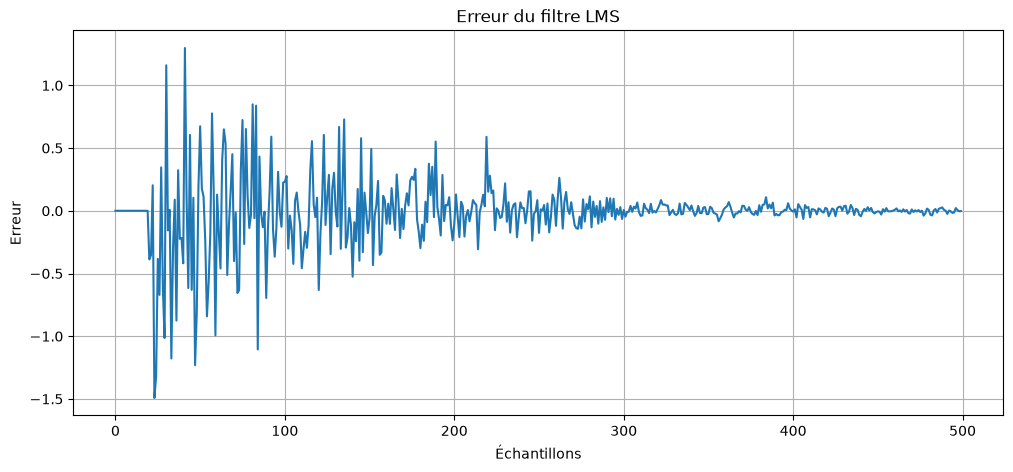

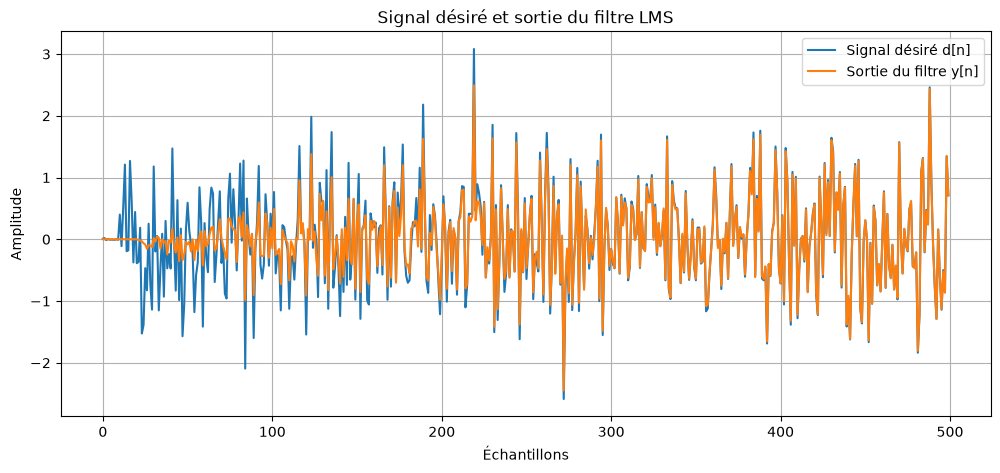

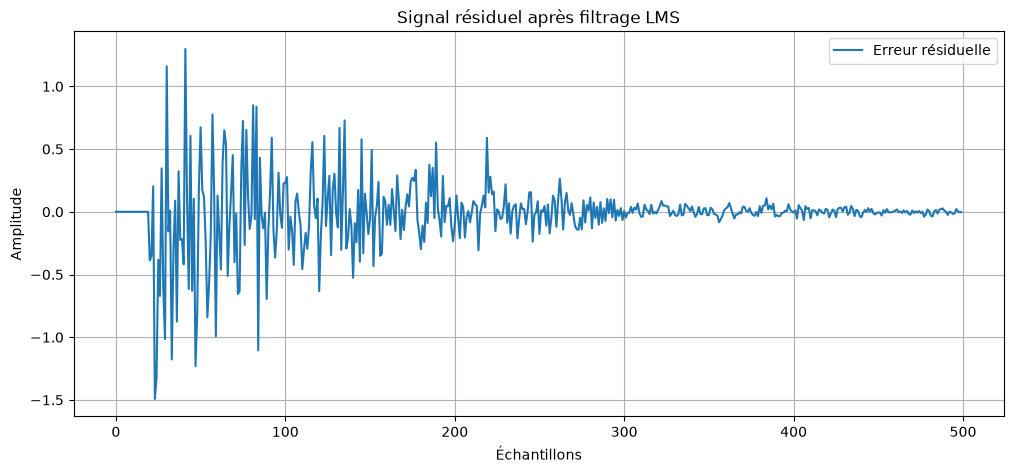

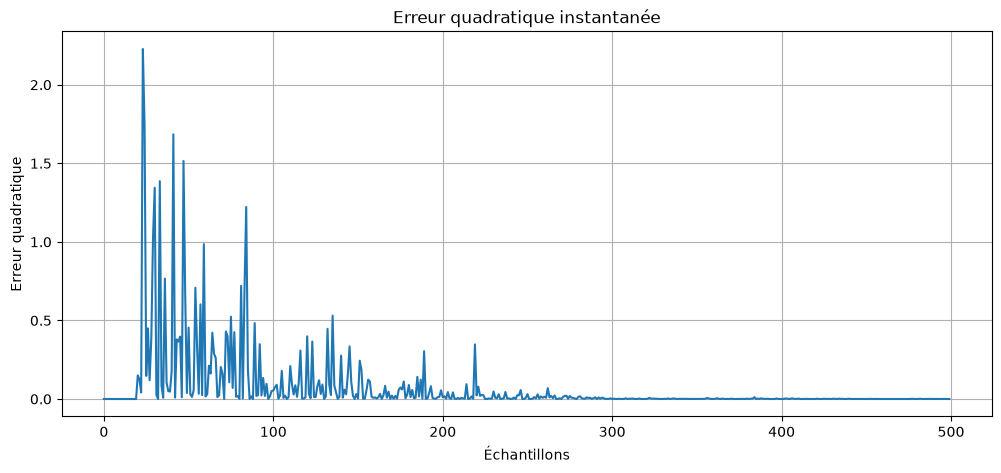

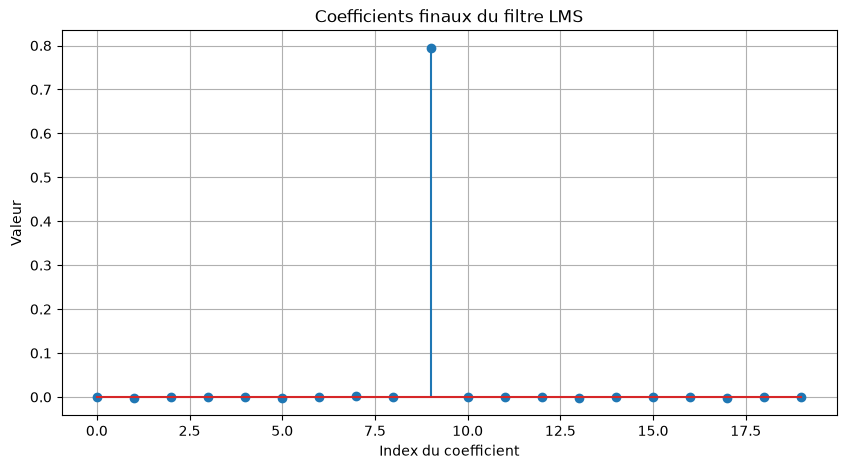

Coefficients finaux du filtre :
[-1.08543725e-03 -1.93593193e-03  1.35293702e-05  4.56052789e-04
  6.50174046e-04 -1.69826051e-03  7.12639464e-04  1.90084526e-03
 -7.39897346e-04  7.94407691e-01 -7.31987499e-04 -5.37394044e-05
 -6.17564882e-04 -1.54872664e-03 -8.91089244e-04  3.34278957e-04
 -2.58108077e-04 -2.33697477e-03 -2.49229668e-04  5.54648439e-04]


In [50]:
import numpy as np
import matplotlib.pyplot as plt

# Implémentation LMS
def lms_filter(x, d, M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N)

    for n in range(M, N):
        x_n = x[n-M:n][::-1]  # inversion pour convolution
        y[n] = np.dot(w, x_n)
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * x_n

    return y, e, w


# Test
# Génération des signaux
np.random.seed(42)

N = 500
x = np.random.randn(N)

# Signal désiré contenant un écho
delay = 10
d = np.zeros(N)
d[delay:] = 0.8 * x[:-delay]

# Ajout du bruit
noise = 0.01 * np.random.randn(N)
d = d + noise

# Paramètres du filtre
M = 20
mu = 0.01

# Application du filtre LMS
y, e, w = lms_filter(x, d, M, mu)

# Tracer l'erreur
plt.figure(figsize=(12, 5))
plt.plot(e)
plt.xlabel("Échantillons")
plt.ylabel("Erreur")
plt.title("Erreur du filtre LMS")
plt.grid()
plt.show()

# Tracé du signal désiré et de la sortie du filtre
plt.figure(figsize=(12, 5))
plt.plot(d, label="Signal désiré d[n]")
plt.plot(y, label="Sortie du filtre y[n]")
plt.xlabel("Échantillons")
plt.ylabel("Amplitude")
plt.title("Signal désiré et sortie du filtre LMS")
plt.legend()
plt.grid()
plt.show()

# Tracé du signal résiduel
plt.figure(figsize=(12, 5))
plt.plot(e, label="Erreur résiduelle")
plt.xlabel("Échantillons")
plt.ylabel("Amplitude")
plt.title("Signal résiduel après filtrage LMS")
plt.legend()
plt.grid()
plt.show()

# Erreur quadratique
plt.figure(figsize=(12, 5))
plt.plot(e**2)
plt.xlabel("Échantillons")
plt.ylabel("Erreur quadratique")
plt.title("Erreur quadratique instantanée")
plt.grid()
plt.show()

# Coefficients finaux
plt.figure(figsize=(10, 5))
plt.stem(w)
plt.xlabel("Index du coefficient")
plt.ylabel("Valeur")
plt.title("Coefficients finaux du filtre LMS")
plt.grid()
plt.show()

print("Coefficients finaux du filtre :")
print(w)


### Principe de l'algorithme LMS

L'algorithme LMS (Least Mean Squares) est un algorithme adaptatif qui ajuste les coefficients d'un filtre afin de minimiser l'erreur entre le signal désiré et la sortie du filtre.

Le filtre utilise un vecteur d'entrée \(x_n\) de longueur \(M\). La sortie du filtre est calculée par :

\[
y[n]=w^T[n]x_n
\]

L'erreur est définie par :

\[
e[n]=d[n]-y[n]
\]

Les coefficients sont ensuite mis à jour selon :

\[
w[n+1]=w[n]+\mu e[n]x_n
\]

où :

- \(M\) : longueur du filtre.
- \(\mu\) : pas d'adaptation.
- \(w[n]\) : vecteur des coefficients.
- \(d[n]\) : signal désiré.
- \(y[n]\) : sortie du filtre.
- \(e[n]\) : erreur.

### Conclusion

L'algorithme LMS adapte automatiquement les coefficients du filtre à chaque itération. L'objectif est de réduire l'erreur entre le signal désiré et la sortie estimée. L'évolution de l'erreur permet d'observer le comportement de l'adaptation et la capacité du filtre à estimer le signal désiré.

# 5. Livrable Semaine 10

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---